# Custom CNN 1: penjelasan langkah demi langkah

Notebook ini mempelajari klasifikasi empat tingkat keparahan jerawat dari ACNE04 menggunakan **custom CNN TensorFlow/Keras yang dilatih dari nol**. Setiap bagian berisi penjelasan, lalu satu sel kode yang dijelaskan. Jalankan kode secara berurutan karena variabel dari sel sebelumnya digunakan pada sel berikutnya.

Alur utama: **instalasi -> konfigurasi -> dataset/subset -> train/validation/test -> preprocessing -> CNN -> training -> evaluasi -> prediksi foto baru**.

Pada notebook ini, CNN menggunakan empat convolution, Global Average Pooling, dan output Softmax empat kelas. Labelnya adalah 0 Mild, 1 Moderate, 2 Severe, dan 3 Very Severe. Bagian v2 hanya menyaring keanggotaan training, dengan label tetap berasal dari ACNE04.

Sel kode, parameter model, dan output eksekusi yang sudah tersimpan dipertahankan. Penjelasan membantu membaca implementasi yang ada; hasil lama tidak berarti model telah dilatih ulang saat dokumentasi ini ditambahkan.

## 1. Memasang dependensi

**Tujuan:** menyiapkan library tambahan yang dipakai pada sel berikutnya.

- `!pip` menjalankan perintah instalasi dari notebook; `-q` mengurangi keluaran instalasi.
- `datasets` mengambil dataset Hugging Face. `scikit-learn` menyediakan pembagian data, bobot kelas, dan metrik evaluasi.
- `pillow` mengolah gambar, `requests` mengambil anotasi lewat HTTP, dan `tqdm` menampilkan progress bar.

Sel ini belum memasang TensorFlow, NumPy, pandas, atau Matplotlib; notebook mengasumsikan semuanya sudah tersedia pada lingkungan Python. Setelah instalasi berhasil, lanjutkan ke import. Jika kernel perlu di-restart, jalankan kembali sel import sebelum melanjutkan.

In [ ]:
!pip -q install datasets scikit-learn pillow requests tqdm

## 2. Import library, seed, dan pemeriksaan perangkat

**Tujuan:** menyediakan alat untuk memuat data, membangun CNN, dan menilai hasilnya.

`numpy` mengolah array gambar/label, `pandas` membuat tabel, `matplotlib` menggambar grafik, dan `json` menyimpan hasil. `Path` mengatur lokasi file, sedangkan `Image` membaca dan mengubah gambar. TensorFlow/Keras menyediakan layer, optimizer, dan proses training.

Bagian `sklearn` mengimpor fungsi untuk:

- membagi train/validation secara stratified melalui `train_test_split`;
- menghitung bobot kelas melalui `compute_class_weight`;
- menghitung accuracy, macro-F1, MAE, classification report, dan confusion matrix.

`SEED = 42` menetapkan nilai awal generator acak melalui `set_random_seed`, sehingga pengacakan lebih mudah diulang. Seed tidak menjamin hasil identik pada perangkat atau versi library berbeda.

**Membaca output:** versi TensorFlow menunjukkan lingkungan yang dipakai. Daftar GPU yang kosong berarti TensorFlow tidak mendeteksi GPU; kode tetap dapat berjalan memakai CPU, dengan waktu training bergantung perangkat.

In [ ]:
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error
)

from tensorflow.keras import layers, regularizers

SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 3. Konfigurasi eksperimen dan lokasi hasil

**Tujuan:** mengumpulkan pengaturan utama sebelum data diproses.

| Variabel | Arti |
|---|---|
| `MODE_DATA` | `acne04` memakai seluruh bagian training awal; `acne04_v2` menyaring training berdasarkan daftar nama gambar v2. |
| `UKURAN = 224` | Setiap gambar disiapkan menjadi 224 x 224 piksel. |
| `BATCH_SIZE = 32` | Maksimal 32 gambar diproses dalam satu batch; batch terakhir bisa lebih kecil. |
| `EPOCHS = 60` | Batas maksimum 60 putaran training; early stopping dapat menghentikannya lebih awal. |
| `nama_kelas` | Urutan label: 0 Mild, 1 Moderate, 2 Severe, 3 Very Severe. |

`assert` memastikan mode valid. `folder_hasil` membuat folder di `/content`, sesuai penggunaan notebook di Google Colab. Jika dijalankan lokal, lokasi ini perlu disesuaikan dengan direktori yang dapat ditulis.

`path_model` menentukan lokasi checkpoint `model_terbaik.keras`. Folder dipisahkan berdasarkan mode, tetapi menjalankan ulang mode yang sama masih dapat menimpa file hasil sebelumnya.

In [ ]:
MODE_DATA = "acne04"  # Pilihan: "acne04" atau "acne04_v2"

UKURAN = 224
BATCH_SIZE = 32
EPOCHS = 60

nama_kelas = ["Mild", "Moderate", "Severe", "Very Severe"]

assert MODE_DATA in ["acne04", "acne04_v2"]

# Folder terpisah agar hasil kedua percobaan tidak tertimpa
folder_hasil = Path("/content") / f"hasil_cnn_{MODE_DATA}"
folder_hasil.mkdir(parents=True, exist_ok=True)

path_model = str(folder_hasil / "model_terbaik.keras")

## 4. Memuat ACNE04 dan membuat tabel metadata

**Tujuan:** mengambil gambar beserta label severity, lalu menyiapkan informasi untuk pembagian data.

`load_dataset(...)` memuat ACNE04 dari Hugging Face. `data = dataset["train"]` mengambil container bernama `train`. **Nama container ini tidak berarti semua isinya boleh menjadi data training:** kode selanjutnya memakai kolom `split` untuk menentukan anggota train dan test.

Tabel `metadata` berisi:

- `file_name`: identitas nama gambar;
- `level`: target severity berupa integer 0 sampai 3;
- `split`: keanggotaan train/test dari dataset.

Target klasifikasi berasal dari `level`, bukan nama file atau jumlah lesi. `metadata.head()` menampilkan lima baris awal untuk memeriksa struktur. Gambar akan dibaca dan diubah menjadi array pada bagian preprocessing.

In [ ]:
dataset = load_dataset("Layered-Labs/ACNE04")
data = dataset["train"]

print("Jumlah gambar ACNE04:", len(data))
print("Kolom:", data.column_names)

# Metadata saja, tidak perlu membuka seluruh gambar
metadata = pd.DataFrame({
    "file_name": list(data["file_name"]),
    "level": list(data["level"]),
    "split": list(data["split"])
})

print(metadata.head())

README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

Jumlah gambar ACNE04: 1457
Kolom: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']
        file_name  level  split
0    levle0_0.jpg      0  train
1    levle0_1.jpg      0  train
2   levle0_10.jpg      1  train
3  levle0_100.jpg      0  train
4  levle0_101.jpg      0  train


## 5. Mencocokkan gambar dengan daftar ACNE04-v2

**Tujuan:** menandai gambar ACNE04 yang namanya tercantum pada berkas anotasi v2 untuk percobaan subset training.

`requests.get` mengunduh JSON dengan batas waktu 60 detik. `raise_for_status()` menghentikan proses jika respons HTTP menunjukkan kegagalan. Salinan JSON disimpan sebagai `anotasi_v2.json` agar sumber percobaan dapat ditelusuri.

Fungsi `nama_file_saja` membuang komponen folder dan menangani pemisah `/` maupun `\`. Nama yang sudah diseragamkan dipakai untuk membuat kolom `ada_di_v2`, yang bernilai benar jika gambar terdapat dalam daftar v2.

**Yang perlu dipahami:** sel ini hanya menggunakan daftar nama gambar v2. Target `level` tetap berasal dari ACNE04 yang dimuat sebelumnya; kode tidak mengganti label severity memakai anotasi v2. Sel ini juga tetap mengunduh JSON saat mode yang dipilih adalah `acne04`.

**Membaca output:** jumlah nama yang cocok menunjukkan banyaknya kandidat subset. Daftar `tidak_ditemukan` menunjukkan nama v2 yang tidak ada pada sumber Hugging Face. Pemeriksaan terakhir memastikan ada setidaknya satu kecocokan, bukan menjamin seluruh nama cocok. Keunikan nama file yang diperiksa di sini belum merupakan audit duplikat piksel.

In [ ]:
url_v2 = (
    "https://raw.githubusercontent.com/"
    "AIpourlapeau/acne04v2/main/Acne04-v2_annotations.json"
)

respons = requests.get(url_v2, timeout=60)
respons.raise_for_status()

anotasi_v2 = respons.json()

# Simpan salinan anotasi untuk dokumentasi percobaan
with open(folder_hasil / "anotasi_v2.json", "w") as f:
    json.dump(anotasi_v2, f)


def nama_file_saja(nama):
    # Menangani nama yang mungkin mengandung folder
    return str(nama).replace("\\", "/").split("/")[-1]


nama_v2 = {
    nama_file_saja(item["file_name"])
    for item in anotasi_v2["images"]
}

metadata["nama_cocok"] = metadata["file_name"].map(nama_file_saja)
metadata["ada_di_v2"] = metadata["nama_cocok"].isin(nama_v2)

# Pastikan setiap nama file sumber unik
assert metadata["nama_cocok"].is_unique

tidak_ditemukan = nama_v2 - set(metadata["nama_cocok"])

print("Jumlah nama gambar dalam JSON v2:", len(nama_v2))
print("Jumlah yang cocok dengan Hugging Face:",
      metadata["ada_di_v2"].sum())
print("Jumlah yang tidak ditemukan:", len(tidak_ditemukan))

if tidak_ditemukan:
    print("Contoh nama yang tidak ditemukan:",
          sorted(tidak_ditemukan)[:10])

assert metadata["ada_di_v2"].sum() > 0, (
    "Tidak ada nama gambar yang cocok. Periksa sumber dataset."
)

Jumlah nama gambar dalam JSON v2: 1204
Jumlah yang cocok dengan Hugging Face: 1204
Jumlah yang tidak ditemukan: 0


## 6. Membagi train, validation, dan test

**Tujuan:** memisahkan data untuk pembelajaran, pemilihan model, dan evaluasi akhir.

1. `np.where` mengambil indeks canonical train dan test dari kolom `split`.
2. `train_test_split` mengambil 20% canonical training sebagai validation. `stratify` mempertahankan proporsi kelas sejauh pembagian memungkinkan, dan `random_state=SEED` membuat pengacakan dapat diulang.
3. Pada mode `acne04_v2`, hanya bagian training yang disaring memakai `mask_v2`. Validation dan test tetap berasal dari ACNE04 lengkap.
4. `data.select` mengambil baris dataset sesuai indeks akhir.

**Peran tiap bagian:** training memperbarui bobot CNN; validation dipakai untuk memilih checkpoint dan mengatur proses training; test digunakan setelah konfigurasi dipilih. Pada mode `acne04`, output yang tersimpan menunjukkan 932 training, 233 validation, dan 292 test. Angka training mode v2 dapat berbeda karena penyaringan.

Tiga pemeriksaan `isdisjoint` memastikan indeks antarbagian tidak tumpang tindih. Ini belum mendeteksi gambar berpiksel sama pada indeks berbeda atau pasien yang sama. Pemeriksaan berikutnya memastikan setiap bagian memiliki keempat kelas.

`distribusi` menunjukkan jumlah gambar tiap kelas. Seluruh membership disimpan ke `pembagian_data.csv` untuk dokumentasi eksperimen.

In [ ]:
level = metadata["level"].to_numpy(dtype=int)
split = metadata["split"].to_numpy()
mask_v2 = metadata["ada_di_v2"].to_numpy()

# Mengambil pembagian train dan test dari ACNE04
idx_train_asli = np.where(split == "train")[0]
idx_test_asli = np.where(split == "test")[0]

# Membagi bagian training menjadi train dan validation
idx_train_awal, idx_val_awal = train_test_split(
    idx_train_asli,
    test_size=0.2,
    random_state=SEED,
    stratify=level[idx_train_asli]
)

# Validation dan test memakai ACNE04 lengkap
idx_val = idx_val_awal.copy()
idx_test = idx_test_asli.copy()

# Memilih data training sesuai mode
if MODE_DATA == "acne04_v2":
    idx_train = idx_train_awal[mask_v2[idx_train_awal]]
else:
    idx_train = idx_train_awal.copy()

# Memastikan indeks tidak tumpang tindih
assert set(idx_train).isdisjoint(idx_val)
assert set(idx_train).isdisjoint(idx_test)
assert set(idx_val).isdisjoint(idx_test)

# Mengambil data
data_train = data.select(idx_train.tolist())
data_val = data.select(idx_val.tolist())
data_test = data.select(idx_test.tolist())

# Menampilkan distribusi kelas
distribusi = pd.DataFrame({
    "Kelas": nama_kelas,
    "Training": np.bincount(level[idx_train], minlength=4),
    "Validation": np.bincount(level[idx_val], minlength=4),
    "Test": np.bincount(level[idx_test], minlength=4)
})

print("Mode:", MODE_DATA)
print(distribusi.to_string(index=False))

print("\nJumlah training:", len(data_train))
print("Jumlah validation:", len(data_val))
print("Jumlah test:", len(data_test))

# Memastikan semua kelas tersedia
for nama, indeks in [
    ("training", idx_train),
    ("validation", idx_val),
    ("test", idx_test)
]:
    assert np.all(np.bincount(level[indeks], minlength=4) > 0), (
        f"Ada kelas kosong pada {nama}."
    )

# Menyimpan daftar pembagian data
bagian_data = []

for nama, indeks in [
    ("train", idx_train),
    ("validation", idx_val),
    ("test", idx_test)
]:
    bagian = metadata.iloc[indeks].copy()
    bagian["bagian"] = nama
    bagian_data.append(bagian)

pd.concat(bagian_data).to_csv(
    folder_hasil / "pembagian_data.csv",
    index=False
)

Mode: acne04
      Kelas  Training  Validation  Test
       Mild       328          82   103
   Moderate       405         101   127
     Severe       117          29    36
Very Severe        82          21    26

Jumlah training: 932
Jumlah validation: 233
Jumlah test: 292


## 7. Menyiapkan array gambar dan label

**Tujuan:** mengubah objek gambar menjadi bentuk numerik yang dapat diproses CNN.

`siapkan_gambar` melakukan tiga langkah: mengubah gambar ke RGB, melakukan resize bilinear menjadi 224 x 224, lalu mengubahnya menjadi array NumPy `uint8`. Tiga kanal RGB menjelaskan angka 3 pada bentuk input model.

Resize dilakukan langsung ke bentuk persegi, sehingga proporsi foto yang semula tidak persegi dapat berubah. Kode ini tidak menggunakan letterbox atau crop wajah.

`siapkan_data` menyediakan array `X` untuk seluruh gambar pada bagian yang dipilih dan array `y` untuk label `level` bertipe `int32`. Progress bar menunjukkan kemajuan pembacaan gambar.

**Bentuk hasil:** `X` memiliki ukuran `(jumlah_gambar, 224, 224, 3)` dan `y` memiliki satu label integer per gambar. Array disimpan dalam RAM. Piksel masih berada pada rentang 0-255; normalisasi 0-1 dilakukan di dalam model, sehingga tidak perlu dilakukan lagi di sel ini.

Hanya training dan validation yang disiapkan sekarang. Test baru disiapkan pada sel evaluasi test.

In [ ]:
def siapkan_gambar(gambar):
    gambar = gambar.convert("RGB")
    gambar = gambar.resize(
        (UKURAN, UKURAN),
        Image.Resampling.BILINEAR
    )
    return np.asarray(gambar, dtype=np.uint8)


def siapkan_data(data_gambar):
    X = np.empty(
        (len(data_gambar), UKURAN, UKURAN, 3),
        dtype=np.uint8
    )

    y = np.asarray(data_gambar["level"], dtype=np.int32)

    for i, baris in enumerate(tqdm(data_gambar)):
        X[i] = siapkan_gambar(baris["image"])

    return X, y


X_train, y_train = siapkan_data(data_train)
X_val, y_val = siapkan_data(data_val)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

  0%|          | 0/932 [00:00<?, ?it/s]

  0%|          | 0/233 [00:00<?, ?it/s]

Training: (932, 224, 224, 3)
Validation: (233, 224, 224, 3)


## 8. Melihat satu gambar dari setiap kelas severity

**Tujuan:** memeriksa contoh gambar hasil preprocessing untuk keempat kelas: Mild, Moderate, Severe, dan Very Severe.

`enumerate(nama_kelas)` menelusuri setiap kelas sesuai urutan label 0-3. `np.flatnonzero(y_train == label)` mencari indeks gambar training yang memiliki label tersebut. Kode mengambil indeks pertama (`indeks_kelas[0]`), sehingga pemilihan gambar tidak memakai sampling acak.

Setiap subplot menampilkan satu gambar dari kelas yang berbeda dengan judul nama severity. Jika suatu kelas tidak memiliki gambar, subplot menampilkan teks "Tidak ada gambar". Gambar berasal dari `X_train`, sehingga preprocessing-nya sama dengan input training model.

`subplot` mengatur susunan gambar; `axis("off")` menyembunyikan sumbu; `tight_layout()` merapikan jarak. Jalankan ulang sel kode ini untuk menghasilkan visualisasi yang baru. Satu contoh per kelas membantu pemeriksaan visual, tetapi belum mewakili seluruh variasi gambar dalam kelas tersebut.

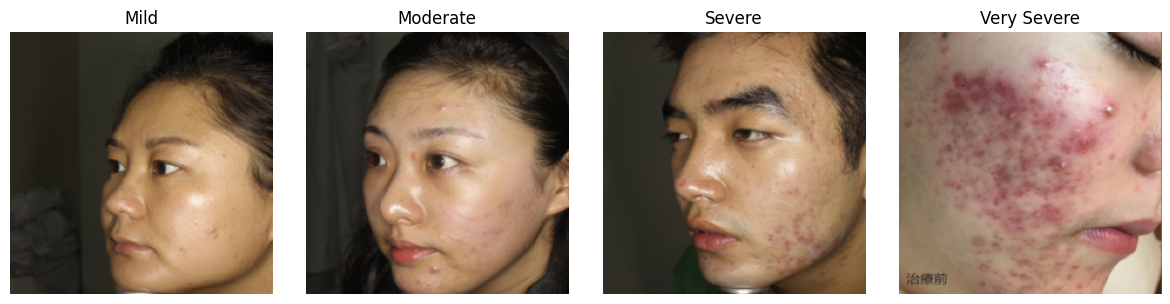

In [ ]:
plt.figure(figsize=(12, 3))

for label, nama in enumerate(nama_kelas):
    plt.subplot(1, len(nama_kelas), label + 1)

    # Ambil gambar pertama yang tersedia untuk kelas ini, tanpa sampling acak.
    indeks_kelas = np.flatnonzero(y_train == label)
    if indeks_kelas.size > 0:
        indeks_gambar = indeks_kelas[0]
        plt.imshow(X_train[indeks_gambar])
    else:
        plt.text(0.5, 0.5, "Tidak ada gambar", ha="center", va="center")

    plt.title(nama)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Pipeline TensorFlow dan penanganan kelas tidak seimbang

**Tujuan:** mengirim pasangan gambar-label ke model per batch dan menyesuaikan kontribusi kelas pada loss.

`from_tensor_slices` membuat dataset dari pasangan `X` dan `y`. Pada training, `shuffle` mengacak urutan pasangan tersebut agar model tidak bergantung pada urutan penyimpanan. `batch` mengelompokkan maksimal 32 gambar. `prefetch` menyiapkan batch berikutnya sambil batch saat ini diproses, dengan pengaturan otomatis TensorFlow.

Validation tidak diacak. Urutan ini penting karena hasil prediksinya nanti dibandingkan dengan `y_val` pada posisi yang sama.

Bobot kelas dihitung **hanya dari label training** menggunakan:

`bobot_kelas = jumlah_training / (4 x jumlah_training_di_kelas_tersebut)`.

Kelas yang lebih jarang mendapat bobot lebih besar. Dengan demikian, kesalahannya memberi kontribusi lebih besar pada loss training. Ini tidak menambah atau menggandakan gambar. Dictionary `class_weight` akan diberikan ke `model.fit` pada bagian training.

In [ ]:
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation tidak diacak
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

kelas = np.arange(4)

bobot = compute_class_weight(
    class_weight="balanced",
    classes=kelas,
    y=y_train
)

class_weight = {
    int(k): float(b)
    for k, b in zip(kelas, bobot)
}

print("Class weight:", class_weight)

Class weight: {0: 0.7103658536585366, 1: 0.5753086419753086, 2: 1.9914529914529915, 3: 2.841463414634146}


## 10. Membangun dan mengompilasi custom CNN

**Tujuan:** membangun jaringan yang belajar mengekstraksi fitur gambar dan memprediksi empat severity dari nol.

`clear_session()` membersihkan keadaan global Keras sebelum model dibuat, lalu seed diatur kembali. `Input` menerima gambar RGB berukuran 224 x 224. `Rescaling(1/255)` mengubah piksel menjadi 0-1 di dalam model, sehingga normalisasi ikut tersimpan bersama model.

**Augmentasi training:** `RandomFlip` membalik gambar secara horizontal dan `RandomRotation` memberi rotasi kecil. Keras mengaktifkannya saat training dan menonaktifkannya saat validation/predict.

Empat blok utama memiliki pola `Conv2D -> BatchNormalization -> ReLU`:

- `Conv2D` mempelajari filter 3 x 3. Filter per blok adalah 32, 64, 128, 128. `padding="same"` mempertahankan tinggi/lebar pada convolution dengan stride default 1.
- `he_normal` menentukan inisialisasi bobot yang digunakan bersama ReLU. `use_bias=False` meniadakan bias convolution; setiap convolution diikuti BatchNormalization.
- `BatchNormalization` menormalkan aktivasi dan menyimpan statistik untuk digunakan saat inference.
- `ReLU` mempertahankan nilai positif dan mengubah nilai negatif menjadi nol.
- `MaxPooling2D` mengambil nilai maksimum per area 2 x 2 pada **tiga blok pertama**, sehingga tinggi/lebar berkurang separuh. Blok keempat tidak melakukan pooling.

| Tahap | Bentuk fitur, tanpa dimensi batch |
|---|---|
| Input | 224 x 224 x 3 |
| Blok 1 + MaxPool | 112 x 112 x 32 |
| Blok 2 + MaxPool | 56 x 56 x 64 |
| Blok 3 + MaxPool | 28 x 28 x 128 |
| Blok 4 | 28 x 28 x 128 |
| Global Average Pooling | 128 |
| Dense Softmax | 4 |

`GlobalAveragePooling2D` merata-ratakan setiap kanal menjadi satu nilai, sehingga 128 feature map menjadi vektor 128 angka. `Dropout(0.3)` menonaktifkan secara acak sebagian unit selama training untuk membantu regularisasi. Dense terakhir menghasilkan empat skor Softmax yang jumlahnya satu.

**Pengaturan pembelajaran:** Adam memakai learning rate `0.001`. `sparse_categorical_crossentropy` sesuai untuk label integer 0-3 tanpa one-hot encoding. L2 `1e-4` pada bobot convolution menambahkan penalti bobot besar ke loss. Accuracy mengukur proporsi prediksi kelas yang benar; pembobotan kelas pada loss baru diterapkan saat `fit`.

`model.summary()` memperlihatkan bentuk output dan parameter setiap layer. Output yang tersimpan mencatat **242.404 parameter**, termasuk statistik BatchNormalization yang tidak dilatih lewat gradient.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

inputs = layers.Input(shape=(UKURAN, UKURAN, 3))

# Normalisasi piksel 0–255 menjadi 0–1
x = layers.Rescaling(1.0 / 255)(inputs)

# Augmentasi hanya aktif saat training
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomRotation(
    factor=0.03,
    fill_mode="reflect"
)(x)

# Empat blok convolution
for i, jumlah_filter in enumerate([32, 64, 128, 128]):
    x = layers.Conv2D(
        filters=jumlah_filter,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"conv_{i + 1}"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Pooling hanya pada tiga blok pertama
    if i < 3:
        x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax",
    name="severity"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="DermaScan_CustomCNN"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("Jumlah parameter:", model.count_params())

Model: "DermaScan_CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity (Dense)                │ (None, 4)              │           51

 Total params: 242,404 (946.89 KB)

 Trainable params: 241,700 (944.14 KB)

 Non-trainable params: 704 (2.75 KB)

Jumlah parameter: 242404


## 11. Callback: memilih model dan mengendalikan training

**Tujuan:** memilih checkpoint dengan kemampuan validation terbaik dan menghentikan percobaan ketika peningkatannya berhenti.

`HitungMacroF1` dijalankan pada akhir setiap epoch. Model memprediksi validation, `argmax` mengambil indeks skor Softmax tertinggi, kemudian `f1_score(..., average="macro")` menghitung rata-rata F1 keempat kelas dengan bobot setara. F1 merangkum precision dan recall. `zero_division=0` memberi nilai nol ketika perhitungan tertentu tidak terdefinisi.

Hasil ditambahkan ke `logs["val_macro_f1"]`. Callback ini diletakkan paling awal agar callback berikutnya dapat membaca metrik tersebut.

| Callback | Tindakan |
|---|---|
| `ModelCheckpoint` | Menyimpan model `.keras` hanya ketika validation macro-F1 meningkat; `mode="max"` berarti lebih besar lebih baik. |
| `ReduceLROnPlateau` | Mengalikan learning rate dengan 0,5 setelah 4 epoch tanpa peningkatan; batas bawahnya `1e-6`. |
| `EarlyStopping` | Menghentikan training setelah 12 epoch tanpa peningkatan. |
| `CSVLogger` | Menyimpan riwayat metrik per epoch ke `riwayat_training.csv`. |

`restore_best_weights=False` berarti EarlyStopping tidak otomatis mengembalikan bobot epoch terbaik pada objek `model`. Karena itu, sel training berikutnya secara eksplisit memuat checkpoint terbaik dari file.

In [ ]:
class HitungMacroF1(tf.keras.callbacks.Callback):
    def __init__(self, val_ds, y_val):
        super().__init__()
        self.val_ds = val_ds
        self.y_val = y_val

    def on_epoch_end(self, epoch, logs=None):
        probabilitas = self.model.predict(
            self.val_ds,
            verbose=0
        )

        prediksi = np.argmax(probabilitas, axis=1)

        skor = f1_score(
            self.y_val,
            prediksi,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        if logs is not None:
            logs["val_macro_f1"] = skor

        print(f" — val_macro_f1: {skor:.4f}")


callbacks = [
    # Letakkan pertama agar metrik tersedia bagi callback berikutnya
    HitungMacroF1(val_ds, y_val),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=path_model,
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_macro_f1",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        mode="max",
        patience=12,
        restore_best_weights=False,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(folder_hasil / "riwayat_training.csv")
    )
]

## 12. Menjalankan training dan memuat checkpoint terbaik

**Tujuan:** memperbarui bobot CNN berdasarkan training dan memakai model pilihan validation untuk evaluasi berikutnya.

`model.fit` menjalankan training dengan batas `EPOCHS`. Dalam setiap epoch, TensorFlow melakukan forward pass, menghitung loss berbobot kelas, menghitung gradient melalui backpropagation, dan memperbarui bobot melalui Adam.

`validation_data=val_ds` menilai model pada akhir epoch tanpa memperbarui bobot menggunakan contoh validation. Augmentasi dan dropout tidak aktif pada evaluasi tersebut. Callback menentukan kapan checkpoint disimpan, learning rate diturunkan, atau training dihentikan.

`history` menyimpan metrik per epoch, termasuk accuracy, loss, metrik validation, dan macro-F1 yang ditambahkan callback.

Setelah training selesai, `load_model(path_model, compile=False)` memuat checkpoint dengan validation macro-F1 tertinggi sebagai `model_terbaik`. Model ini dapat langsung dipakai untuk `predict`; konfigurasi compile tidak diperlukan untuk inference. Model terbaik tidak harus berasal dari epoch terakhir.

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks
)

# Muat model dari epoch dengan macro F1 validation terbaik
model_terbaik = tf.keras.models.load_model(
    path_model,
    compile=False
)

print("Model terbaik dimuat dari:", path_model)

Epoch 1/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3028 - loss: 1.4043 — val_macro_f1: 0.1302

Epoch 1: val_macro_f1 improved from None to 0.13016, saving model to /content/hasil_cnn_acne04/model_terbaik.keras

Epoch 1: finished saving model to /content/hasil_cnn_acne04/model_terbaik.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 224s 7s/step - accuracy: 0.3498 - loss: 1.3200 - val_accuracy: 0.3519 - val_loss: 1.5316 - val_macro_f1: 0.1302 - learning_rate: 0.0010
Epoch 2/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.4326 - loss: 1.1286 — val_macro_f1: 0.1302

Epoch 2: val_macro_f1 did not improve from 0.13016
30/30 ━━━━━━━━━━━━━━━━━━━━ 260s 7s/step - accuracy: 0.4088 - loss: 1.2119 - val_accuracy: 0.3519 - val_loss: 1.5297 - val_macro_f1: 0.1302 - learning_rate: 0.0010
Epoch 3/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4194 - loss: 1.1690 — val_macro_f1: 0.1302

Epoch 3: val_macro_f1 did not improve from 0.13016
30/30 ━━━━━━━━━━━━━━━━━━━━ 209s 7s/step - accuracy: 0.4

## 12a. Mengekspor checkpoint terbaik ke TensorFlow Lite (.tflite)

**Tujuan:** menyimpan model yang sudah dilatih sebagai file `.tflite` untuk inference. Jalankan sel ini setelah bagian training/checkpoint, saat `path_model`, `UKURAN`, `nama_kelas`, dan `X_val` sudah tersedia. Output training lama yang terlihat di notebook tidak menggantikan file checkpoint atau variabel pada runtime aktif.

Sel memuat kembali `model_terbaik.keras`, lalu membuat jalur inference khusus arsitektur berurutan Custom CNN 1 dengan layer/bobot yang sama. RandomFlip, RandomRotation, dan Dropout dilewati karena hanya diperlukan saat training; BatchNormalization dipanggil dengan `training=False`. Normalisasi `Rescaling(1/255)` tetap berada dalam model.

Konversi memakai `TFLiteConverter` dalam format **float32**, tanpa quantization, dan hanya operator bawaan TFLite. Sebelum file disimpan, kode membandingkan model Keras asli, jalur inference, dan model TFLite pada maksimal 16 gambar validation: skor harus mendekati satu sama lain dan label prediksi harus sama. Pemeriksaan subset ini bukan jaminan semua foto/perangkat menghasilkan skor identik, dan tidak mengukur ulang accuracy seluruh dataset.

File yang dihasilkan, pada folder yang sama dengan checkpoint:

- `model_terbaik.tflite`: model untuk inference.
- `model_terbaik_tflite.json`: ukuran/dtype input, preprocessing, urutan kelas, dan ringkasan pemeriksaan.

**Input aplikasi:** satu gambar RGB hasil resize bilinear langsung ke 224 x 224, bentuk `[1, 224, 224, 3]`, dtype float32, dan nilai piksel 0-255. Jangan membagi 255 lagi karena normalisasi sudah ada dalam model. **Output:** empat skor Softmax berurutan Mild, Moderate, Severe, Very Severe; gunakan indeks skor terbesar untuk memilih kelas.

Di Colab, file dapat diunduh melalui panel **Files** pada folder hasil mode yang sedang digunakan. Ekspor ini tidak memerlukan training ulang jika checkpoint dan data validation sudah tersedia.

Referensi: [TFLiteConverter](https://www.tensorflow.org/api_docs/python/tf/lite/TFLiteConverter) dan [Interpreter](https://www.tensorflow.org/api_docs/python/tf/lite/Interpreter).


In [ ]:
from pathlib import Path

# Gunakan checkpoint terbaik yang sudah disimpan saat training.
checkpoint_keras = Path(path_model)
if not checkpoint_keras.is_file():
    raise FileNotFoundError(f"Checkpoint belum tersedia: {checkpoint_keras}. Jalankan training dahulu.")
if len(X_val) == 0:
    raise ValueError("X_val diperlukan untuk memeriksa hasil konversi.")

model_ekspor = tf.keras.models.load_model(checkpoint_keras, compile=False)
bentuk_gambar = tuple(model_ekspor.input_shape[1:])
if bentuk_gambar != (UKURAN, UKURAN, 3) or model_ekspor.output_shape[-1] != len(nama_kelas):
    raise ValueError("Ukuran input atau jumlah kelas checkpoint berbeda dari konfigurasi.")

# Buat jalur inference dengan bobot yang sama, tanpa layer augmentasi/dropout.
input_lite = tf.keras.Input(shape=bentuk_gambar, batch_size=1, dtype=tf.float32, name="gambar")
x_lite = input_lite
for layer in model_ekspor.layers:
    if isinstance(layer, (layers.InputLayer, layers.RandomFlip, layers.RandomRotation, layers.Dropout)):
        continue
    if isinstance(layer, layers.BatchNormalization):
        x_lite = layer(x_lite, training=False)
    else:
        x_lite = layer(x_lite)
model_inferensi = tf.keras.Model(input_lite, x_lite, name="DermaScan_Inferensi")

# Ekspor float32 menggunakan operator bawaan TFLite, tanpa quantization.
converter = tf.lite.TFLiteConverter.from_keras_model(model_inferensi)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_model = converter.convert()

# Periksa interface dan bandingkan prediksi pada maksimal 16 gambar validation.
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
detail_input = interpreter.get_input_details()[0]
detail_output = interpreter.get_output_details()[0]
np.testing.assert_array_equal(detail_input["shape"], [1, *bentuk_gambar])
np.testing.assert_array_equal(detail_output["shape"], [1, len(nama_kelas)])
assert detail_input["dtype"] == np.float32 and detail_output["dtype"] == np.float32

indeks_uji = np.linspace(0, len(X_val) - 1, num=min(16, len(X_val)), dtype=int)
selisih_maksimum = 0.0
for indeks in indeks_uji:
    gambar_uji = np.asarray(X_val[indeks:indeks + 1], dtype=np.float32)
    skor_keras = model_ekspor(gambar_uji, training=False).numpy()
    skor_inferensi = model_inferensi(gambar_uji, training=False).numpy()
    np.testing.assert_allclose(skor_keras, skor_inferensi, rtol=1e-5, atol=1e-6)
    interpreter.set_tensor(detail_input["index"], gambar_uji)
    interpreter.invoke()
    skor_lite = interpreter.get_tensor(detail_output["index"])
    np.testing.assert_allclose(skor_keras, skor_lite, rtol=1e-4, atol=1e-4)
    if int(skor_keras.argmax()) != int(skor_lite.argmax()):
        raise ValueError("Label prediksi Keras dan TFLite berbeda; periksa hasil sebelum menyimpan.")
    selisih_maksimum = max(selisih_maksimum, float(np.max(np.abs(skor_keras - skor_lite))))

# Simpan hanya setelah pemeriksaan berhasil.
path_tflite = checkpoint_keras.with_suffix(".tflite")
path_metadata_tflite = checkpoint_keras.with_name(checkpoint_keras.stem + "_tflite.json")
path_tflite.write_bytes(tflite_model)
metadata_tflite = {
    "input_shape": [1, *bentuk_gambar], "input_dtype": "float32",
    "color_mode": "RGB", "resize": "bilinear_direct", "pixel_range": [0, 255],
    "normalization_in_model": True, "class_names": list(nama_kelas),
    "output": "softmax_scores", "tensorflow_version": tf.__version__,
    "validated_samples": int(len(indeks_uji)), "max_abs_difference": selisih_maksimum,
}
path_metadata_tflite.write_text(json.dumps(metadata_tflite, indent=2), encoding="utf-8")
print("Model TFLite:", path_tflite)
print("Ukuran file: %.2f KB" % (path_tflite.stat().st_size / 1024))
print("Metadata input dan kelas:", path_metadata_tflite)
print("Pemeriksaan berhasil pada", len(indeks_uji), "gambar validation.")
print("Selisih skor maksimum:", selisih_maksimum)


Saved artifact at '/tmp/tmpm18jpean'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 224, 224, 3), dtype=tf.float32, name='gambar')
Output Type:
  TensorSpec(shape=(1, 4), dtype=tf.float32, name=None)
Captures:
  138529852929424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852929232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852930192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852920784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852928080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852928272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852926544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852917712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852923472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852925584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138529852928464: TensorSpe

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Model TFLite: /content/hasil_cnn_acne04/model_terbaik.tflite
Ukuran file: 947.93 KB
Metadata input dan kelas: /content/hasil_cnn_acne04/model_terbaik_tflite.json
Pemeriksaan berhasil pada 16 gambar validation.
Selisih skor maksimum: 3.0994415283203125e-06


## 13. Membaca kurva pembelajaran

**Tujuan:** melihat perubahan performa sepanjang training.

Grafik pertama membandingkan accuracy training dan validation. Grafik kedua membandingkan loss. Grafik ketiga menunjukkan validation macro-F1, yaitu metrik yang dipakai untuk memilih checkpoint.

Sumbu horizontal memakai **indeks epoch mulai dari 0**: titik 0 adalah epoch pertama. Accuracy dan macro-F1 yang lebih tinggi berarti lebih baik pada data yang diukur; loss yang lebih rendah berarti objektif pembelajaran lebih kecil.

Jika training terus membaik tetapi validation memburuk secara konsisten, pola tersebut dapat mengindikasikan overfitting. Namun, jangan menilai hanya dari selisih satu titik: training memakai augmentasi, dropout, dan class weight, sedangkan validation tidak. Loss juga mencakup regularisasi L2. Karena kondisi pengukurannya berbeda, gap kedua kurva tidak semata-mata menunjukkan overfitting.

Gunakan validation untuk mengevaluasi perubahan konfigurasi; jangan memilih konfigurasi dari kurva atau hasil test.

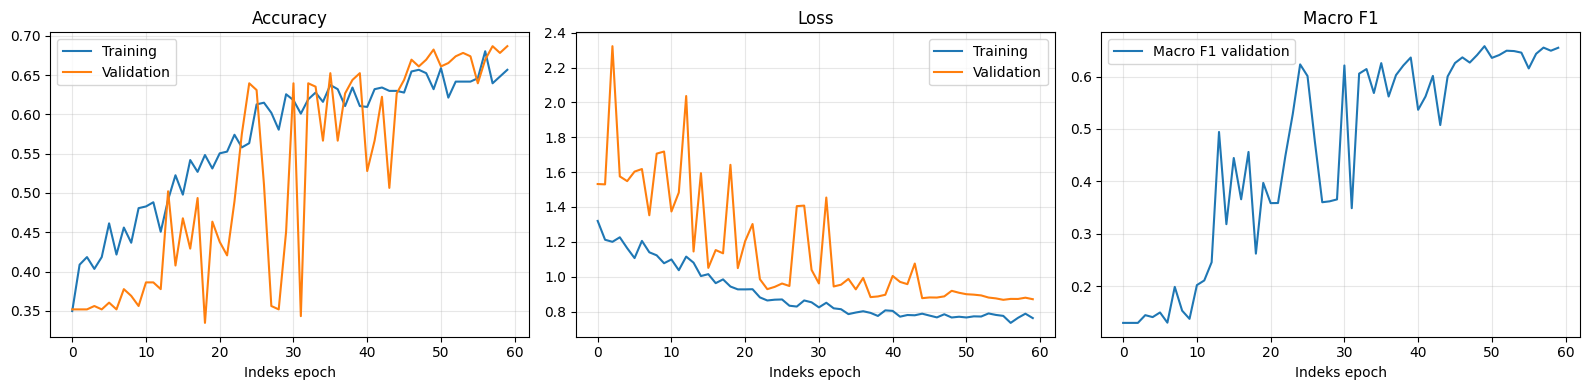

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(history.history["accuracy"], label="Training")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy")
ax[0].legend()

ax[1].plot(history.history["loss"], label="Training")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss")
ax[1].legend()

ax[2].plot(
    history.history["val_macro_f1"],
    label="Macro F1 validation"
)
ax[2].set_title("Macro F1")
ax[2].legend()

for a in ax:
    a.set_xlabel("Indeks epoch")
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 14. Fungsi evaluasi dan hasil validation

**Tujuan:** menilai checkpoint terbaik secara lebih lengkap daripada accuracy saja.

`evaluasi_model` memprediksi skor empat kelas dan mengubahnya menjadi label dengan `argmax`. Fungsi ini menghitung:

| Metrik | Cara membaca |
|---|---|
| Accuracy | Proporsi seluruh gambar yang diprediksi benar. |
| Macro-F1 | Rata-rata F1 empat kelas dengan bobot setara, sehingga kelas besar tidak mendominasi seperti pada accuracy. |
| MAE severity | Rata-rata jarak absolut antara label asli dan prediksi; lebih kecil lebih baik. |

Sebagai contoh MAE, Mild (0) diprediksi Moderate (1) memberi kesalahan 1, sedangkan Mild (0) diprediksi Very Severe (3) memberi kesalahan 3. Ini jarak antar-grade, bukan selisih jumlah lesi. Loss cross-entropy saat training sendiri tidak secara eksplisit menggunakan jarak ordinal ini.

**Classification report:** precision menunjukkan proporsi prediksi suatu kelas yang benar; recall menunjukkan proporsi contoh asli kelas itu yang berhasil ditemukan; F1 menggabungkan keduanya; support adalah jumlah contoh asli per kelas.

**Confusion matrix:** baris menunjukkan kelas asli dan kolom menunjukkan kelas prediksi. Diagonal berisi prediksi benar; nilai di luar diagonal menunjukkan kelas yang tertukar.

Pemanggilan pada sel ini mengevaluasi validation memakai `model_terbaik`, mengembalikan dictionary `hasil_val`, dan menyimpannya sebagai `hasil_validation.json`.

Hasil Validation
accuracy: 0.6824
macro_f1: 0.6580
mae_severity: 0.3348

Classification Report:
              precision    recall  f1-score   support

        Mild       0.73      0.80      0.77        82
    Moderate       0.77      0.59      0.67       101
      Severe       0.41      0.55      0.47        29
 Very Severe       0.65      0.81      0.72        21

    accuracy                           0.68       233
   macro avg       0.64      0.69      0.66       233
weighted avg       0.70      0.68      0.68       233



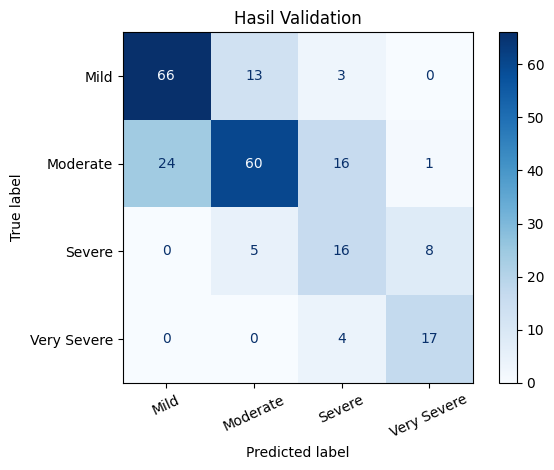

In [ ]:
def evaluasi_model(model, ds, y_asli, judul):
    probabilitas = model.predict(ds, verbose=0)
    prediksi = np.argmax(probabilitas, axis=1)

    hasil = {
        "accuracy": float(accuracy_score(y_asli, prediksi)),
        "macro_f1": float(f1_score(
            y_asli,
            prediksi,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )),
        "mae_severity": float(
            mean_absolute_error(y_asli, prediksi)
        )
    }

    print(judul)
    for nama, nilai in hasil.items():
        print(f"{nama}: {nilai:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_asli,
        prediksi,
        labels=[0, 1, 2, 3],
        target_names=nama_kelas,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_asli,
        prediksi,
        labels=[0, 1, 2, 3]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=nama_kelas
    ).plot(cmap="Blues", values_format="d")

    plt.xticks(rotation=25)
    plt.title(judul)
    plt.tight_layout()
    plt.show()

    return hasil


hasil_val = evaluasi_model(
    model_terbaik,
    val_ds,
    y_val,
    "Hasil Validation"
)

with open(folder_hasil / "hasil_validation.json", "w") as f:
    json.dump(hasil_val, f, indent=2)

## 15. Evaluasi akhir pada test

**Tujuan:** mengukur kemampuan checkpoint terpilih pada bagian test yang tidak digunakan untuk memperbarui bobot atau memilih checkpoint.

`JALANKAN_TEST` saat ini sudah bernilai **True**, sehingga sel akan menyiapkan gambar test, membuat batch tanpa pengacakan, lalu memanggil fungsi evaluasi yang sama. Hasil disimpan ke `hasil_test.json`.

Saat masih memilih konfigurasi berdasarkan validation, ubah flag menjadi `False` dan jalankan test setelah konfigurasi ditentukan. Jika hasil test dipakai berulang untuk menentukan perubahan model, test tidak lagi menjadi evaluasi akhir yang independen.

Preprocessing test sama dengan training/validation, sedangkan augmentasi dan dropout nonaktif ketika `predict`. Output yang sudah ada pada notebook adalah catatan eksekusi sebelumnya; penambahan penjelasan ini tidak menjalankan training atau menghasilkan skor test baru.

  0%|          | 0/292 [00:00<?, ?it/s]

Hasil Test
accuracy: 0.6336
macro_f1: 0.6236
mae_severity: 0.4110

Classification Report:
              precision    recall  f1-score   support

        Mild       0.72      0.74      0.73       103
    Moderate       0.69      0.52      0.59       127
      Severe       0.37      0.53      0.44        36
 Very Severe       0.62      0.92      0.74        26

    accuracy                           0.63       292
   macro avg       0.60      0.68      0.62       292
weighted avg       0.65      0.63      0.63       292



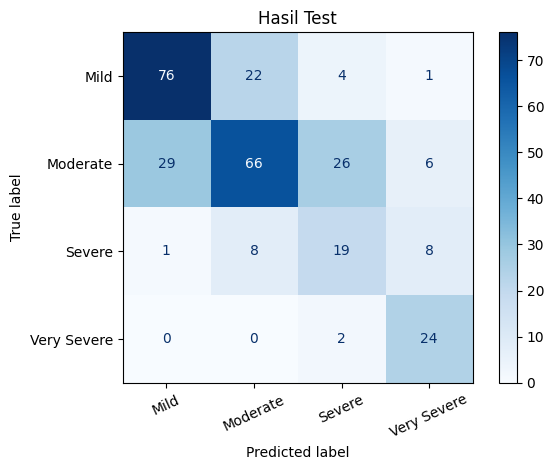

In [ ]:
JALANKAN_TEST = True  # Ubah menjadi True setelah konfigurasi final

if JALANKAN_TEST:
    X_test, y_test = siapkan_data(data_test)

    test_ds = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

    hasil_test = evaluasi_model(
        model_terbaik,
        test_ds,
        y_test,
        "Hasil Test"
    )

    with open(folder_hasil / "hasil_test.json", "w") as f:
        json.dump(hasil_test, f, indent=2)
else:
    print("Test belum dijalankan. Gunakan validation untuk eksperimen.")

## 16. Prediksi foto baru melalui Google Colab

**Tujuan:** mencoba checkpoint terbaik pada foto yang diunggah pengguna.

`files.upload()` membuka pemilih file pada Google Colab. Kode mengambil **file pertama** dari hasil unggahan, membacanya melalui `BytesIO`, dan mengubahnya ke RGB. Sel ini khusus Colab karena mengimpor `google.colab`.

`siapkan_gambar` melakukan resize yang sama dengan training. `expand_dims(..., axis=0)` menambahkan dimensi batch, sehingga satu foto menjadi input berbentuk `(1, 224, 224, 3)`.

`model_terbaik.predict` menghasilkan empat skor Softmax. `[0]` mengambil hasil untuk foto pertama; `argmax` mengambil indeks skor terbesar; indeks tersebut diterjemahkan menjadi nama severity melalui `nama_kelas`. Gambar asli dan label prediksi kemudian ditampilkan.

Jangan membagi piksel dengan 255 lagi sebelum masuk model karena `Rescaling` sudah berada di dalam model. Model selalu memilih salah satu empat severity; tidak ada kelas kulit tanpa jerawat. Skor Softmax adalah keluaran model dan belum merupakan probabilitas klinis yang terkalibrasi.

Saving pevita_pearce.jpg to pevita_pearce.jpg


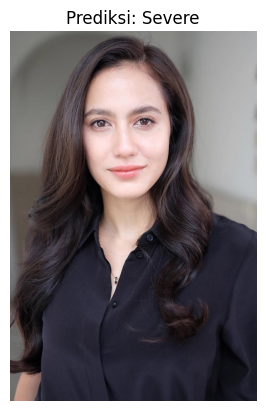

Hasil prediksi: Severe


In [ ]:
from google.colab import files
import io

unggahan = files.upload()

nama_file = next(iter(unggahan))
gambar = Image.open(
    io.BytesIO(unggahan[nama_file])
).convert("RGB")

input_gambar = siapkan_gambar(gambar)
input_gambar = np.expand_dims(input_gambar, axis=0)

probabilitas = model_terbaik.predict(
    input_gambar,
    verbose=0
)[0]

prediksi = int(np.argmax(probabilitas))

plt.imshow(gambar)
plt.axis("off")
plt.title("Prediksi: " + nama_kelas[prediksi])
plt.show()

print("Hasil prediksi:", nama_kelas[prediksi])

## 17. Ringkasan distribusi, confusion matrix, dan riwayat training

**Tujuan:** menampilkan kembali informasi utama untuk analisis atau penulisan laporan.

- Tabel `distribusi` memperlihatkan jumlah contoh setiap kelas pada training, validation, dan test.
- Prediksi validation dihitung lagi menggunakan checkpoint terbaik, lalu ditampilkan sebagai matriks angka. Urutan baris/kolom mengikuti label 0-3; baris adalah kelas asli dan kolom adalah prediksi.
- `DataFrame(history.history)` menyusun metrik setiap epoch menjadi tabel. Kolom yang ditampilkan adalah accuracy/loss training, accuracy/loss validation, dan validation macro-F1.

`round(4)` hanya membulatkan tampilan angka menjadi empat desimal, bukan mengubah bobot model atau hasil training. Indeks baris riwayat dimulai dari 0, sehingga baris 0 mewakili epoch pertama.

Sel ini tidak melatih ulang model. Gunakan distribusi kelas untuk memahami ketimpangan data, confusion matrix untuk melihat pasangan kelas yang sering tertukar, dan riwayat training untuk menjelaskan pemilihan checkpoint.

In [ ]:
print(distribusi.to_string(index=False))

print("\nConfusion matrix validation:")
pred_val = model_terbaik.predict(val_ds, verbose=0).argmax(axis=1)
print(confusion_matrix(y_val, pred_val, labels=[0, 1, 2, 3]))

print("\nRiwayat training:")
kolom = ["accuracy", "val_accuracy", "loss", "val_loss", "val_macro_f1"]
print(pd.DataFrame(history.history)[kolom].round(4).to_string())

      Kelas  Training  Validation  Test
       Mild       328          82   103
   Moderate       405         101   127
     Severe       117          29    36
Very Severe        82          21    26

Confusion matrix validation:
[[66 13  3  0]
 [24 60 16  1]
 [ 0  5 16  8]
 [ 0  0  4 17]]

Riwayat training:
    accuracy  val_accuracy    loss  val_loss  val_macro_f1
0     0.3498        0.3519  1.3200    1.5316        0.1302
1     0.4088        0.3519  1.2119    1.5297        0.1302
2     0.4185        0.3519  1.2001    2.3227        0.1302
3     0.4034        0.3562  1.2261    1.5754        0.1449
4     0.4185        0.3519  1.1636    1.5483        0.1412
5     0.4614        0.3605  1.1067    1.6030        0.1500
6     0.4217        0.3519  1.2055    1.6178        0.1306
7     0.4560        0.3777  1.1400    1.3525        0.1988
8     0.4367        0.3691  1.1226    1.7060        0.1535
9     0.4807        0.3562  1.0772    1.7182        0.1378
10    0.4828        0.3863  1.0989    1.3

In [ ]:
print(path_tflite)
print("File tersedia:", path_tflite.exists())

/content/hasil_cnn_acne04/model_terbaik.tflite
File tersedia: True
